# Comparative Implementation of Machine Learning Regression Algorithms
**Name:** Muhammad Ibrahim Asghar  
**Registration No:** FA23-BAI-046  
**Dataset:** Housing Prices Dataset (Kaggle)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


file_path = '/content/drive/MyDrive/Intro to CV/housing.csv'
df = pd.read_csv(file_path)
print("Dataset Shape:", df.shape)
display(df.head())

# 1. Handle missing values (total_bedrooms has NaNs)
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

# 2. One-hot encode categorical column (ocean_proximity)
df_encoded = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True)

# 3. Clean column names (XGBoost rejects '<', '[', ']' in feature names)
df_encoded.columns = df_encoded.columns.str.replace('<', 'less_than_', regex=False)

# Features (X) and Target (y)
X = df_encoded.drop('median_house_value', axis=1)
y = df_encoded['median_house_value']

# 80:20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature Scaling (for Linear Regression, Neural Network, and KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Dictionary to store all results for final comparison
results = {}

def evaluate_and_plot(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    results[name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

    print(f"--- {name} ---")
    print(f"MAE:  {mae:,.2f}")
    print(f"MSE:  {mse:,.2f}")
    print(f"RMSE: {rmse:,.2f}")
    print(f"R²:   {r2:.4f}\n")

    plt.figure(figsize=(6, 4))
    plt.scatter(y_true, y_pred, alpha=0.4, color='royalblue', edgecolors='none')
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', lw=2)
    plt.xlabel('Actual Median House Value ($)')
    plt.ylabel('Predicted Median House Value ($)')
    plt.title(f'{name}: Actual vs Predicted')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

Dataset Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 1. Linear Regression

--- Linear Regression ---
MAE:  50,670.74
MSE:  4,908,476,721.16
RMSE: 70,060.52
R²:   0.6254



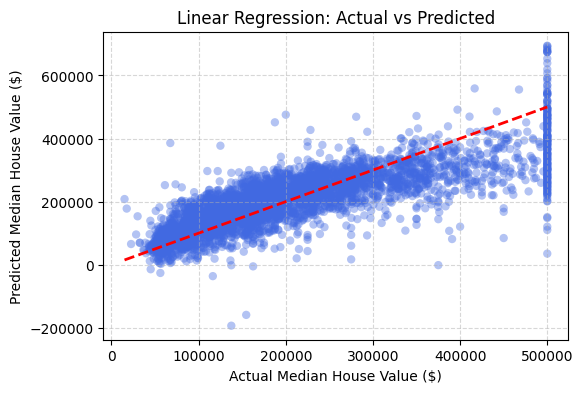

In [2]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

evaluate_and_plot("Linear Regression", y_test, y_pred_lr)

## 2. Decision Tree Regression

--- Decision Tree Regression ---
MAE:  44,180.85
MSE:  4,865,868,836.96
RMSE: 69,755.78
R²:   0.6287



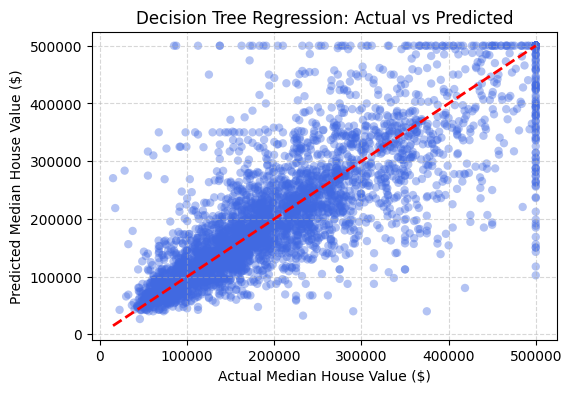

In [3]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

evaluate_and_plot("Decision Tree Regression", y_test, y_pred_dt)

## 3. Random Forest Regression

--- Random Forest Regression ---
MAE:  31,639.37
MSE:  2,404,745,975.12
RMSE: 49,038.21
R²:   0.8165



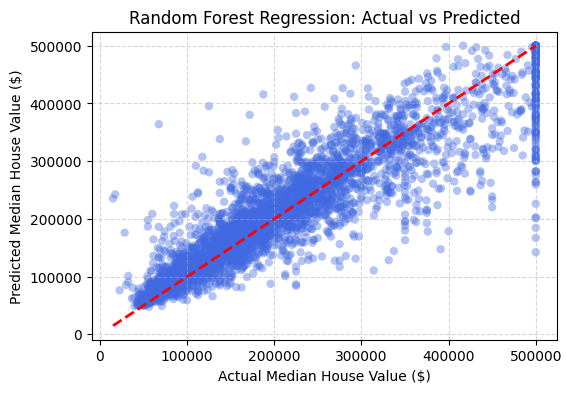

In [4]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

evaluate_and_plot("Random Forest Regression", y_test, y_pred_rf)

## 4. Neural Network Regression

--- Neural Network Regression ---
MAE:  36,395.75
MSE:  2,936,378,007.70
RMSE: 54,188.36
R²:   0.7759



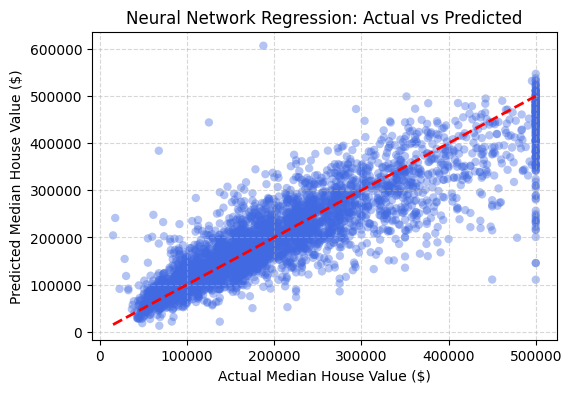

In [5]:
from sklearn.neural_network import MLPRegressor

# Scale target y for better Neural Network convergence
y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel()

nn = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True, random_state=42)
nn.fit(X_train_scaled, y_train_scaled)

y_pred_nn_scaled = nn.predict(X_test_scaled)
y_pred_nn = y_scaler.inverse_transform(y_pred_nn_scaled.reshape(-1, 1)).ravel()

evaluate_and_plot("Neural Network Regression", y_test, y_pred_nn)

## 5. XGBoost Regression

--- XGBoost Regression ---
MAE:  32,430.71
MSE:  2,349,141,133.69
RMSE: 48,467.94
R²:   0.8207



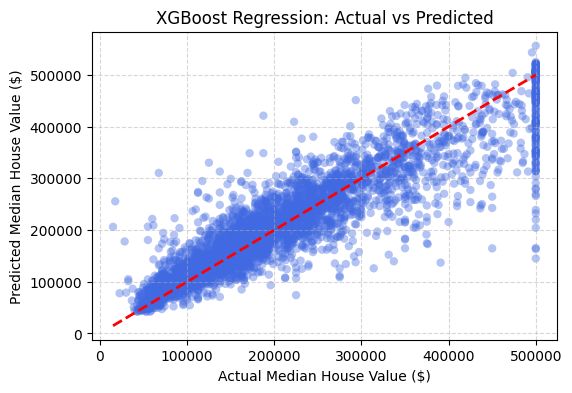

In [6]:
from xgboost import XGBRegressor

xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

evaluate_and_plot("XGBoost Regression", y_test, y_pred_xgb)

## 6. K-Nearest Neighbors (KNN) Regression

--- KNN Regression ---
MAE:  40,854.40
MSE:  3,765,913,279.63
RMSE: 61,367.04
R²:   0.7126



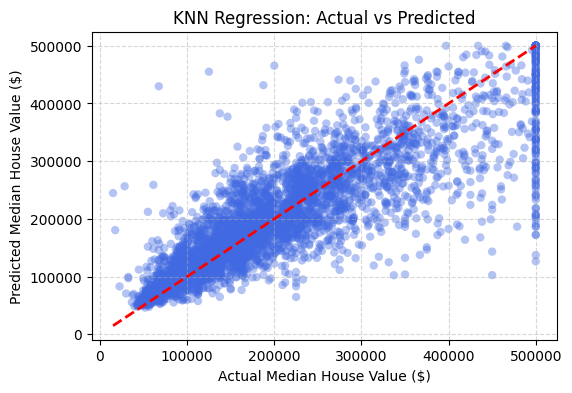

In [7]:
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

evaluate_and_plot("KNN Regression", y_test, y_pred_knn)

## Comparative Performance Summary

In [8]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by='R2', ascending=False)
display(results_df.style.format({'MAE': '{:,.2f}', 'MSE': '{:,.2f}', 'RMSE': '{:,.2f}', 'R2': '{:.4f}'}))

# Print plain text version so you can easily copy-paste it back to me
print(results_df.to_string())

,MAE,MSE,RMSE,R2
XGBoost Regression,"32,430.71","2,349,141,133.69","48,467.94",0.8207
Random Forest Regression,"31,639.37","2,404,745,975.12","49,038.21",0.8165
Neural Network Regression,"36,395.75","2,936,378,007.70","54,188.36",0.7759
KNN Regression,"40,854.40","3,765,913,279.63","61,367.04",0.7126
Decision Tree Regression,"44,180.85","4,865,868,836.96","69,755.78",0.6287
Linear Regression,"50,670.74","4,908,476,721.16","70,060.52",0.6254


                                    MAE           MSE          RMSE        R2
XGBoost Regression         32430.707229  2.349141e+09  48467.939235  0.820732
Random Forest Regression   31639.373406  2.404746e+09  49038.209338  0.816489
Neural Network Regression  36395.754069  2.936378e+09  54188.356754  0.775919
KNN Regression             40854.397771  3.765913e+09  61367.037403  0.712615
Decision Tree Regression   44180.854409  4.865869e+09  69755.779954  0.628676
Linear Regression          50670.738241  4.908477e+09  70060.521845  0.625424


--- Neural Network Regression ---
MAE:  36,395.75
MSE:  2,936,378,007.70
RMSE: 54,188.36
R²:   0.7759



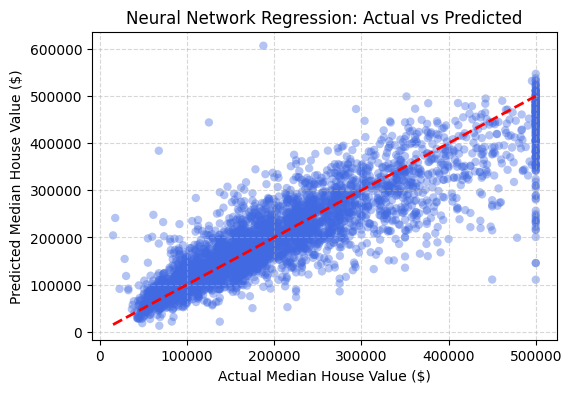

In [9]:
from sklearn.neural_network import MLPRegressor

# Scale target y for better Neural Network convergence
y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel()

nn = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True, random_state=42)
nn.fit(X_train_scaled, y_train_scaled)

y_pred_nn_scaled = nn.predict(X_test_scaled)
y_pred_nn = y_scaler.inverse_transform(y_pred_nn_scaled.reshape(-1, 1)).ravel()

evaluate_and_plot("Neural Network Regression", y_test, y_pred_nn)